5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 169ms/step
=== Baseline Model Report ===
              precision    recall  f1-score   support

        calm       0.97      0.98      0.97        58
    stressed       0.99      0.97      0.98        77

    accuracy                           0.98       135
   macro avg       0.98      0.98      0.98       135
weighted avg       0.98      0.98      0.98       135

=== LSTM Model Report ===
              precision    recall  f1-score   support

        calm       0.88      0.91      0.90        58
    stressed       0.93      0.91      0.92        77

    accuracy                           0.91       135
   macro avg       0.91      0.91      0.91       135
weighted avg       0.91      0.91      0.91       135



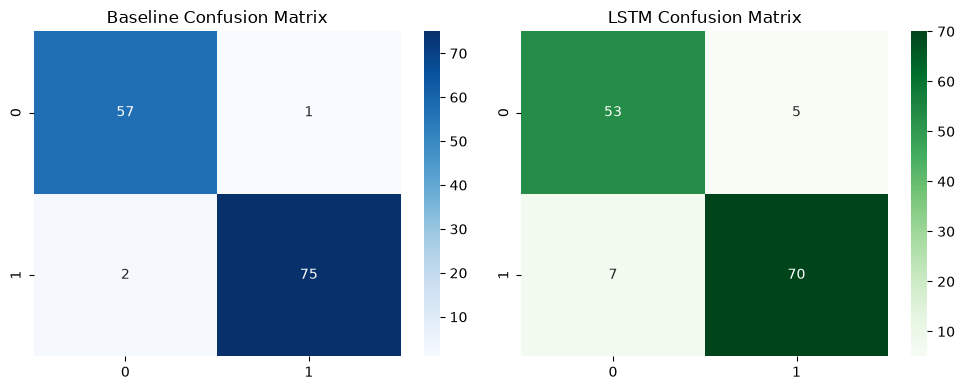

In [1]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

X_agg_test = np.load("../data/X_agg_test.npy")
X_seq_test = np.load("../data/X_seq_test.npy")
y_test = np.load("../data/y_test.npy")

baseline = tf.keras.models.load_model("../models/baseline_model.h5")
lstm = tf.keras.models.load_model("../models/lstm_model.h5")

pred_baseline = (baseline.predict(X_agg_test) > 0.5).astype(int)
pred_lstm = (lstm.predict(X_seq_test) > 0.5).astype(int)

print("=== Baseline Model Report ===")
print(classification_report(y_test, pred_baseline, target_names=["calm", "stressed"]))

print("=== LSTM Model Report ===")
print(classification_report(y_test, pred_lstm, target_names=["calm", "stressed"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(confusion_matrix(y_test, pred_baseline), annot=True, fmt="d", ax=axes[0], cmap="Blues")
axes[0].set_title("Baseline Confusion Matrix")
sns.heatmap(confusion_matrix(y_test, pred_lstm), annot=True, fmt="d", ax=axes[1], cmap="Greens")
axes[1].set_title("LSTM Confusion Matrix")
plt.tight_layout()
plt.savefig("../data/confusion_matrices.png")
plt.show()